In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
import time
import tracemalloc
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
print("Library siap.")

Library siap.


In [29]:
df = pd.read_csv('properti_multi_kota.csv')
print("Shape awal:", df.shape)
df.head()

Shape awal: (34422, 8)


,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08


In [30]:
SAMPLE_SIZE  = 15_000
RANDOM_STATE = 42

df['sumber_data'] = df['sumber'].str.split('/').str[0]

pct_usia = df['usia_bangunan'].isnull().mean() * 100
df = df.drop(columns=['sumber', 'usia_bangunan'])
print(f"[1] Drop usia_bangunan   : {pct_usia:.1f}% kosong -> kolom dibuang")

before = len(df)
df = df.drop_duplicates()
print(f"[2] Hapus duplikat       : {before} -> {len(df)}")

df['lokasi'] = df['lokasi'].str.strip().str.title()

numeric_cols = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'harga']
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())
print(f"[3] Missing values diisi  : {df[numeric_cols].isnull().sum().sum()} tersisa")

before = len(df)
df = df[df['harga'].between(50_000_000, 50_000_000_000)]
df = df[df['luas_m2'].between(10, 5000)]
df = df[df['luas_bangunan'].between(10, 2000)]
df = df[df['jumlah_kamar'].between(0, 20)]
df = df[df['jumlah_kamar_mandi'].between(0, 20)]
print(f"[4] Hapus outlier ekstrem : {before} -> {len(df)}")

median_harga = df['harga'].median()
df['kategori_harga'] = np.where(df['harga'] > median_harga, 'Mahal', 'Murah')

df = df.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)
print(f"[5] Sampling              : {SAMPLE_SIZE} data (random_state={RANDOM_STATE})")

FEATURES = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'harga']
X = df[FEATURES].copy()
for col in ['luas_m2', 'luas_bangunan', 'harga']:
    X[col] = np.log1p(X[col])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(f"[6] Data siap clustering  : {X_scaled.shape}")
print(f"[7] Fitur                 : {FEATURES}")

[1] Drop usia_bangunan   : 86.1% kosong -> kolom dibuang
[2] Hapus duplikat       : 34422 -> 30565
[3] Missing values diisi  : 0 tersisa
[4] Hapus outlier ekstrem : 30565 -> 29909
[5] Sampling              : 15000 data (random_state=42)
[6] Data siap clustering  : (15000, 5)
[7] Fitur                 : ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'harga']


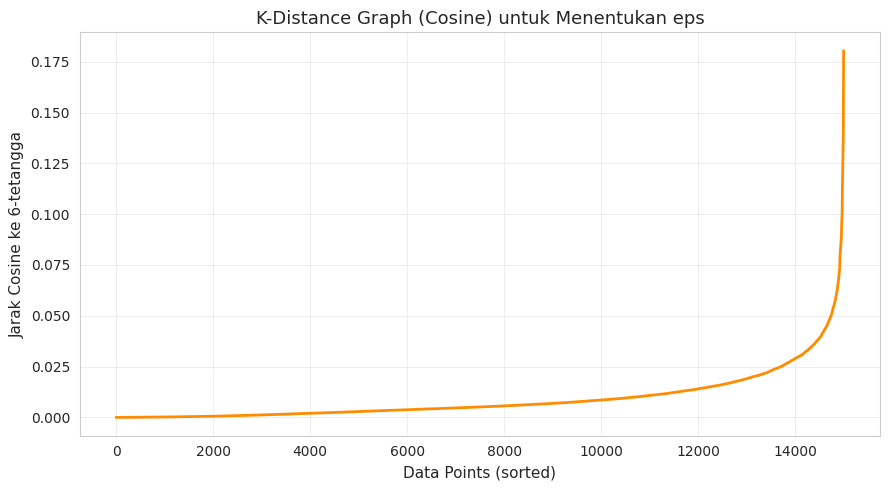

Kandidat eps berdasarkan persentil:
  Persentil 85: 0.0175
  Persentil 90: 0.0229
  Persentil 92: 0.0261
  Persentil 95: 0.0329
  Persentil 97: 0.0407


In [31]:
MIN_SAMPLES = 6  # sama dengan Manhattan & Euclidean agar fair

neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric='cosine')
distances, _ = neighbors.fit(X_scaled).kneighbors(X_scaled)
distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(distances, color='darkorange', linewidth=2)
plt.xlabel('Data Points (sorted)', fontsize=11)
plt.ylabel(f'Jarak Cosine ke {MIN_SAMPLES}-tetangga', fontsize=11)
plt.title('K-Distance Graph (Cosine) untuk Menentukan eps', fontsize=13)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Kandidat eps berdasarkan persentil:")
for p in [85, 90, 92, 95, 97]:
    print(f"  Persentil {p}: {np.percentile(distances, p):.4f}")

In [32]:
print(f"min_samples = {MIN_SAMPLES}")
print(f"{'eps':>7} | {'cluster':>7} | {'noise':>5} | keterangan")
print("-" * 52)
for eps_c in np.arange(0.040, 0.0561, 0.002).round(4):
    lab = DBSCAN(eps=eps_c, min_samples=MIN_SAMPLES, metric='cosine').fit_predict(X_scaled)
    nc = len(set(lab)) - (1 if -1 in lab else 0)
    nn = list(lab).count(-1)
    ket = "<== 3 cluster (target tercapai)" if nc == 3 else ""
    print(f"{eps_c:>7} | {nc:>7} | {nn:>5} | {ket}")

min_samples = 6
    eps | cluster | noise | keterangan
----------------------------------------------------
   0.04 |       2 |   203 | 
  0.042 |       2 |   179 | 
  0.044 |       3 |   157 | <== 3 cluster (target tercapai)
  0.046 |       3 |   136 | <== 3 cluster (target tercapai)
  0.048 |       3 |   120 | <== 3 cluster (target tercapai)
   0.05 |       3 |   109 | <== 3 cluster (target tercapai)
  0.052 |       3 |    93 | <== 3 cluster (target tercapai)
  0.054 |       3 |    90 | <== 3 cluster (target tercapai)
  0.056 |       3 |    82 | <== 3 cluster (target tercapai)


In [33]:
EPS_VALUE = 0.048

tracemalloc.start()
start_time = time.time()

dbscan = DBSCAN(eps=EPS_VALUE, min_samples=MIN_SAMPLES, metric='cosine')
labels = dbscan.fit_predict(X_scaled)

exec_time = time.time() - start_time
_, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

df['cluster'] = labels
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("="*55)
print("HASIL DBSCAN (COSINE)")
print("="*55)
print(f"eps                  : {EPS_VALUE}")
print(f"min_samples          : {MIN_SAMPLES}")
print(f"Jumlah cluster       : {n_clusters}")
print(f"Jumlah noise/outlier : {n_noise} ({n_noise/len(df)*100:.2f}%)")
print(f"Waktu eksekusi       : {exec_time:.4f} detik")
print(f"Peak memory          : {peak/1024:.2f} KB")
print("\nDistribusi cluster:")
print(df['cluster'].value_counts().sort_index())

HASIL DBSCAN (COSINE)
eps                  : 0.048
min_samples          : 6
Jumlah cluster       : 3
Jumlah noise/outlier : 120 (0.80%)
Waktu eksekusi       : 2.7371 detik
Peak memory          : 2098135.86 KB

Distribusi cluster:
cluster
-1      120
 0    14865
 1        8
 2        7
Name: count, dtype: int64


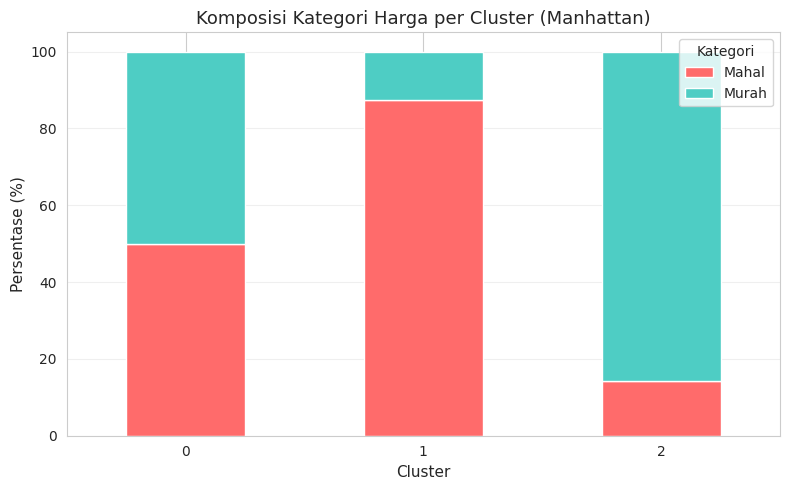

Persentase kategori harga per cluster (%):
kategori_harga  Mahal  Murah
cluster                     
0               49.78  50.22
1               87.50  12.50
2               14.29  85.71


In [34]:
cluster_only = df[df['cluster'] != -1]

comp = pd.crosstab(cluster_only['cluster'], cluster_only['kategori_harga'],
                   normalize='index') * 100

comp.plot(kind='bar', stacked=True, figsize=(8, 5),
          color=['#FF6B6B', '#4ECDC4'], edgecolor='white')
plt.xlabel('Cluster', fontsize=11)
plt.ylabel('Persentase (%)', fontsize=11)
plt.title('Komposisi Kategori Harga per Cluster (Manhattan)', fontsize=13)
plt.legend(title='Kategori', loc='upper right')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("Persentase kategori harga per cluster (%):")
print(comp.round(2))

In [35]:
top_lokasi = df['lokasi'].value_counts().head(10).index
print("Distribusi 10 lokasi terbanyak per cluster:")
print(pd.crosstab(df['cluster'], df.loc[df['lokasi'].isin(top_lokasi), 'lokasi']))

print("\nDistribusi sumber data per cluster:")
print(pd.crosstab(df['cluster'], df['sumber_data']))

print("\nDistribusi kategori harga per cluster:")
print(pd.crosstab(df['cluster'], df['kategori_harga']))

Distribusi 10 lokasi terbanyak per cluster:
lokasi   Bekasi  Bogor  Depok  Jakarta Selatan  Jakarta Utara  \
cluster                                                         
-1            2      0      1                0              1   
 0          482    379    441              276            300   
 1            0      0      0                0              0   
 2            1      0      0                0              0   

lokasi   Kabupaten Bogor  Kabupaten Tangerang  Surabaya  Tangerang  \
cluster                                                              
-1                     1                    0         4          5   
 0                   347                  573       719        428   
 1                     0                    0         2          0   
 2                     0                    0         0          0   

lokasi   Tangerang Selatan  
cluster                     
-1                       0  
 0                     304  
 1                       1  

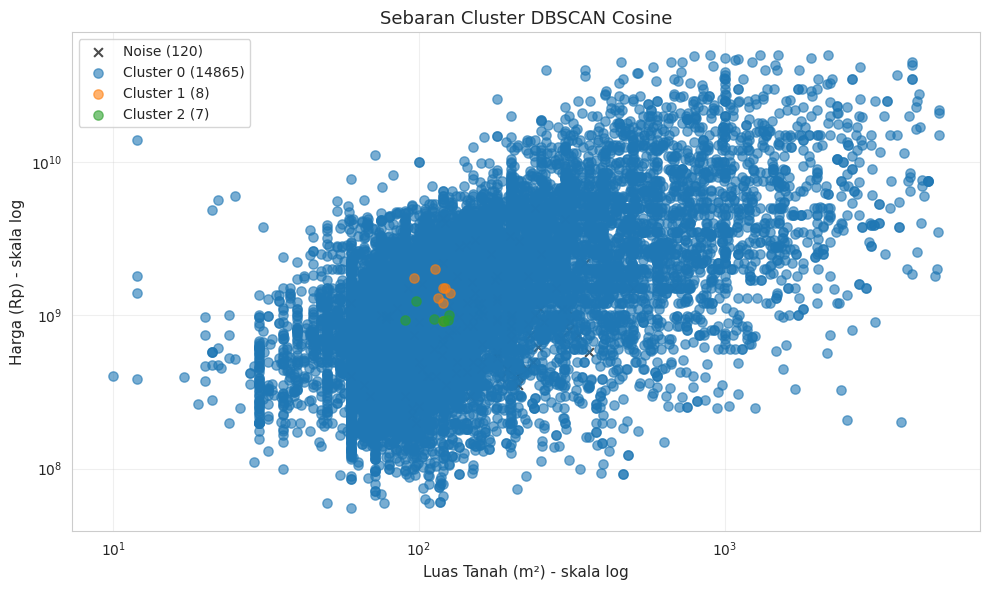

In [36]:
plt.figure(figsize=(10, 6))
for label in sorted(df['cluster'].unique()):
    subset = df[df['cluster'] == label]
    if label == -1:
        plt.scatter(subset['luas_m2'], subset['harga'], c='black', marker='x',
                    s=40, alpha=0.7, label=f'Noise ({len(subset)})')
    else:
        plt.scatter(subset['luas_m2'], subset['harga'], s=45, alpha=0.6,
                    label=f'Cluster {label} ({len(subset)})')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Luas Tanah (m²) - skala log', fontsize=11)
plt.ylabel('Harga (Rp) - skala log', fontsize=11)
plt.title('Sebaran Cluster DBSCAN Cosine', fontsize=13)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

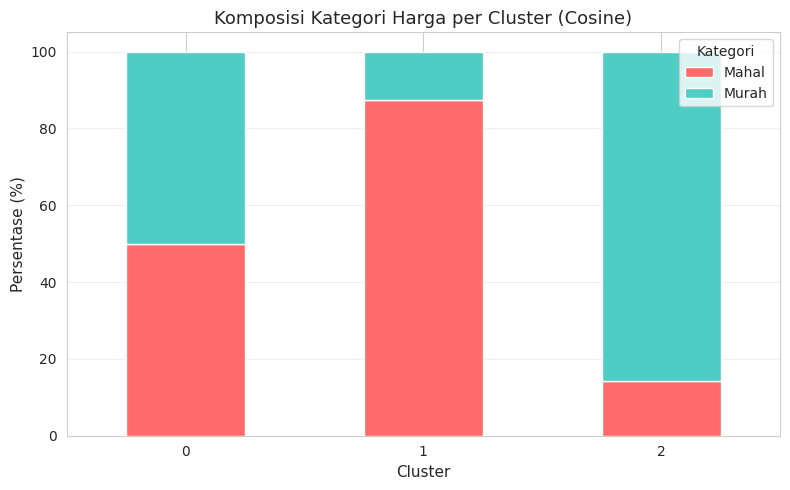

Persentase kategori harga per cluster (%):
kategori_harga  Mahal  Murah
cluster                     
0               49.78  50.22
1               87.50  12.50
2               14.29  85.71


In [37]:
comp = pd.crosstab(cluster_only['cluster'], cluster_only['kategori_harga'],
                   normalize='index') * 100

comp.plot(kind='bar', stacked=True, figsize=(8, 5),
          color=['#FF6B6B', '#4ECDC4'], edgecolor='white')
plt.xlabel('Cluster', fontsize=11)
plt.ylabel('Persentase (%)', fontsize=11)
plt.title('Komposisi Kategori Harga per Cluster (Cosine)', fontsize=13)
plt.legend(title='Kategori', loc='upper right')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("Persentase kategori harga per cluster (%):")
print(comp.round(2))

In [38]:
mask = df['cluster'] != -1
sil_score = silhouette_score(X_scaled[mask], df.loc[mask, 'cluster'], metric='cosine')
print(f"Silhouette Score (Cosine): {sil_score:.4f}")

Silhouette Score (Cosine): -0.2674


In [39]:
hasil_dbscan = {
    'Metode'              : 'DBSCAN',
    'Distance Metric'     : 'Cosine',
    'Jumlah Cluster'      : n_clusters,
    'Jumlah Noise'        : n_noise,
    'Waktu Eksekusi (s)'  : round(exec_time, 4),
    'Peak Memory (KB)'    : round(peak / 1024, 2),
    'Silhouette Score'    : round(sil_score, 4),
    'Parameter'           : f'eps={EPS_VALUE}, min_samples={MIN_SAMPLES}'
}
pd.DataFrame([hasil_dbscan]).T

,0
Metode,DBSCAN
Distance Metric,Cosine
Jumlah Cluster,3
Jumlah Noise,120
Waktu Eksekusi (s),2.7371
Peak Memory (KB),2098135.86
Silhouette Score,-0.2674
Parameter,"eps=0.048, min_samples=6"
